In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Parameters
LAMBDA_ARRIVALS = 1.5  # Poisson arrival rate per lane
DISCHARGE_RATE = 3     # Max vehicles passing per green signal
MAX_QUEUE_BIN = 5      # Max discretized level for queue state
STEPS_PER_EPISODE = 50 # Time steps per episode (simulated day)

# RL Hyperparameters
ALPHA = 0.1    # Learning rate
GAMMA = 0.95   # Discount factor
EPSILON = 0.1  # Exploration rate

In [3]:
def get_state(queues, current_phase):
    binned_queues = tuple(min(q // 2, MAX_QUEUE_BIN) for q in queues)
    return binned_queues + (current_phase,)

In [4]:
def environment_step(queues, current_phase, action):
    if action == 1:
        current_phase = 1 - current_phase

    queues = list(queues)

    if current_phase == 0:
        queues[0] = max(0, queues[0] - DISCHARGE_RATE)
        queues[1] = max(0, queues[1] - DISCHARGE_RATE)
    else:
        queues[2] = max(0, queues[2] - DISCHARGE_RATE)
        queues[3] = max(0, queues[3] - DISCHARGE_RATE)


    arrivals = np.random.poisson(LAMBDA_ARRIVALS, size=4)
    for i in range(4):
        queues[i] += arrivals[i]

    reward = -sum(queues)
    next_state = get_state(queues, current_phase)

    return next_state, reward, queues, current_phase

In [5]:
def choose_action(q_table, state, epsilon):
    if np.random.rand() < epsilon:
        return np.random.choice([0, 1])

    q_vals = q_table.get(state, [0.0, 0.0])
    return np.argmax(q_vals)

In [6]:
def evaluate_fixed_cycle(num_episodes, switch_interval=5):
    avg_queues_per_episode = []

    for _ in range(num_episodes):
        queues = [0, 0, 0, 0]
        current_phase = 0
        total_queue = 0

        for step in range(STEPS_PER_EPISODE):
            action = 1 if (step > 0 and step % switch_interval == 0) else 0
            _, reward, queues, current_phase = environment_step(queues, current_phase, action)
            total_queue += sum(queues)

        avg_queues_per_episode.append(total_queue / STEPS_PER_EPISODE)

    return np.mean(avg_queues_per_episode)

In [7]:
def train_sarsa(num_episodes):
    q_table = {}
    history_avg_queues = []

    for ep in range(num_episodes):
        queues = [0, 0, 0, 0]
        current_phase = 0
        state = get_state(queues, current_phase)
        action = choose_action(q_table, state, EPSILON)

        total_queue = 0

        for _ in range(STEPS_PER_EPISODE):
            next_state, reward, queues, current_phase = environment_step(queues, current_phase, action)
            next_action = choose_action(q_table, next_state, EPSILON)

            if state not in q_table:
                q_table[state] = [0.0, 0.0]
            if next_state not in q_table:
                q_table[next_state] = [0.0, 0.0]

            # Update Q-value using SARSA rule
            td_target = reward + GAMMA * q_table[next_state][next_action]
            td_error = td_target - q_table[state][action]
            q_table[state][action] += ALPHA * td_error

            state = next_state
            action = next_action
            total_queue += sum(queues)

        history_avg_queues.append(total_queue / STEPS_PER_EPISODE)

    return q_table, history_avg_queues

In [8]:
baseline_avg_queue = evaluate_fixed_cycle(num_episodes=1000)
print(f"Fixed-Cycle Baseline Average Queue Length: {baseline_avg_queue:.2f}")

Fixed-Cycle Baseline Average Queue Length: 28.84


In [9]:
# 5,000 episodes
q_table_5k, history_5k = train_sarsa(num_episodes=5000)
print(f"SARSA (5,000 Episodes) Final Avg Queue: {np.mean(history_5k[-100:]):.2f}")

SARSA (5,000 Episodes) Final Avg Queue: 24.04


In [10]:
# 10,000 episodes
q_table_10k, history_10k = train_sarsa(num_episodes=10000)
print(f"SARSA (10,000 Episodes) Final Avg Queue: {np.mean(history_10k[-100:]):.2f}")

SARSA (10,000 Episodes) Final Avg Queue: 24.83


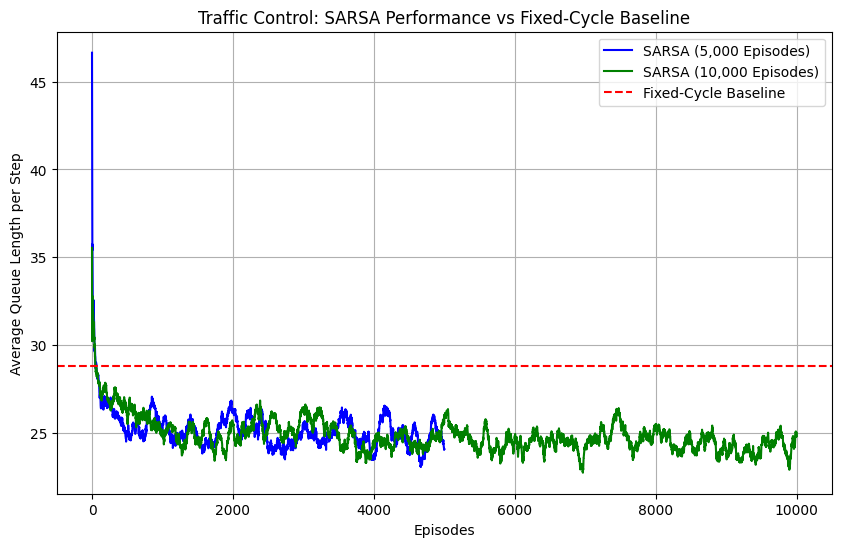

In [11]:
def smooth(data, window=100):
    return [np.mean(data[max(0, i - window):i + 1]) for i in range(len(data))]

# Plot performance curves
plt.figure(figsize=(10, 6))
plt.plot(smooth(history_5k), label='SARSA (5,000 Episodes)', color='blue')
plt.plot(smooth(history_10k), label='SARSA (10,000 Episodes)', color='green')
plt.axhline(y=baseline_avg_queue, color='red', linestyle='--', label='Fixed-Cycle Baseline')

plt.title('Traffic Control: SARSA Performance vs Fixed-Cycle Baseline')
plt.xlabel('Episodes')
plt.ylabel('Average Queue Length per Step')
plt.legend()
plt.grid(True)
plt.show()